In [1]:

%pip install torch torchvision
%pip install torch matplotlib
%pip install numpy  


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


In [16]:

import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch version: 2.15.0+cpu
CUDA available: False


In [3]:

from pathlib import Path

# Dataset directory (relative to the notebook location)
DATA_DIR = Path("miniImage").resolve()

# Verify the dataset directory exists
assert DATA_DIR.is_dir(), f"Dataset directory not found: {DATA_DIR}"

print("Dataset location:", DATA_DIR)
print("Contents:", [p.name for p in DATA_DIR.iterdir()])


Dataset location: D:\VUB\2nd year\Deep learning\project\miniImage
Contents: ['map_clsloc.txt', 'preprocess.py', 'test', 'train']


In [4]:
#If it is not downloaded uncomment this cell

# !pip -q install kagglehub

# import kagglehub
# from pathlib import Path

# # Download latest version
# DATA_DIR = Path(kagglehub.dataset_download("ctrnngtrung/miniimagenet"))

# print("Path to dataset files:", DATA_DIR)

In [5]:
import torch
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# Training: preprocessing + data augmentation
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.2, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

# Testing: preprocessing only
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),# 224 x 224 / 16 x 16 = 196 patches
    transforms.ToTensor()
])

train_dataset = datasets.ImageFolder(
    DATA_DIR / "train",
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    DATA_DIR / "test",
    transform=test_transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Number of classes:", len(train_dataset.classes))

print("Same classes in both splits:",
      train_dataset.classes == test_dataset.classes)

print("First 5 classes:", train_dataset.classes[:5])

image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Pixel range:", image.min().item(), image.max().item())
print("Class index:", label)


Training images: 50000
Testing images: 10000
Number of classes: 100
Same classes in both splits: True
First 5 classes: ['n01532829', 'n01558993', 'n01704323', 'n01749939', 'n01770081']
Image shape: torch.Size([3, 224, 224])
Image dtype: torch.float32
Pixel range: 0.0313725508749485 1.0
Class index: 0


In [6]:
# DataLoaders
from torch.utils.data import DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

# Verify one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Pixel range:", images.min().item(), images.max().item())

Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])
Image dtype: torch.float32
Pixel range: 0.0 1.0


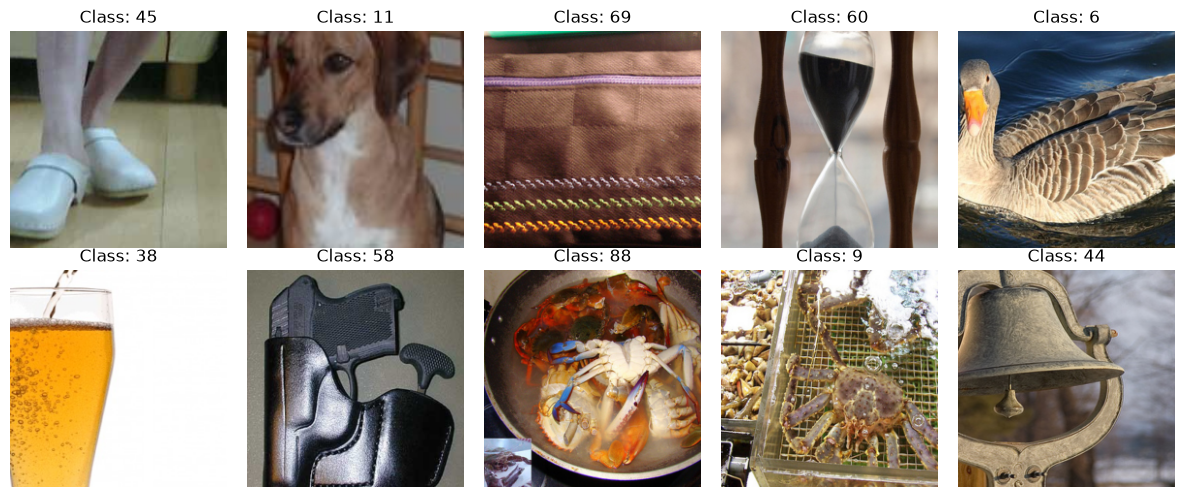

In [7]:
#Visualization

import matplotlib.pyplot as plt
import random

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# Select 10 different classes
selected_classes = random.sample(
    range(len(train_dataset.classes)), 10
)

for ax, class_idx in zip(axes.flat, selected_classes):

    # Find an image belonging to the selected class
    image_idx = next(
        i for i, (_, label) in enumerate(train_dataset.samples)
        if label == class_idx
    )

    image, label = train_dataset[image_idx]

    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(f"Class: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()


## Block 1: Patch Embedding

Patch embedding converts images into sequences of learnable
feature vectors (tokens) for the Vision Transformer.

1. **Patchification:** Divide each 224 × 224 RGB image into
   non-overlapping 16 × 16 patches, producing 196 patches.

2. **Linear Projection:** Each patch contains 16 × 16 × 3 = 768
   pixel values, projected into a 1024-dimensional feature
   vector (ViT-Large embedding dimension).

**Input:**  [B, 3, 224, 224]

**Output:** [B, 196, 1024]

We implement patchification and linear projection together
using a Conv2d layer with kernel_size = stride = 16.


In [8]:

import torch
import torch.nn as nn

# Patch embedding parameters
patch_size = 16
embed_dim = 1024

# Patchification + linear projection
patch_embed = nn.Conv2d(
    in_channels=3,
    out_channels=embed_dim,
    kernel_size=patch_size,
    stride=patch_size
)


In [9]:

# Get a batch from the existing DataLoader
images, labels = next(iter(train_loader))

# Apply patch embedding
x = patch_embed(images)

print("After projection:", x.shape)

# Flatten spatial dimensions and arrange as tokens
x = x.flatten(2).transpose(1, 2)

print("Patch embeddings:", x.shape)


After projection: torch.Size([64, 1024, 14, 14])
Patch embeddings: torch.Size([64, 196, 1024])



## Block 2: Positional Embedding & Random Masking

**Positional Embedding**
- Add fixed 2D sine-cosine positional embeddings to all 196 patches.
- Preserve spatial information without changing token dimensions.

**Random Masking**
- Randomly remove 75% of patches without replacement.
- Keep 49 visible patches and mask 147 patches.
- Save the mask and restoration indices for the decoder.


In [10]:

import numpy as np

def get_1d_sincos_pos_embed(embed_dim, positions):
    """
    positions: array of spatial coordinates
    output: [number_of_positions, embed_dim]
    """
    assert embed_dim % 2 == 0

    omega = np.arange(embed_dim // 2, dtype=np.float64)
    omega /= embed_dim / 2.0
    omega = 1.0 / (10000 ** omega)

    positions = np.asarray(positions).reshape(-1)
    angles = np.einsum("m,d->md", positions, omega)

    return np.concatenate(
        [np.sin(angles), np.cos(angles)],
        axis=1
    )


def get_2d_sincos_pos_embed(embed_dim, grid_size, cls_token=True):
    """
    Returns:
        [grid_size**2 + 1, embed_dim] if cls_token=True
    """
    assert embed_dim % 4 == 0

    grid_h = np.arange(grid_size, dtype=np.float32)
    grid_w = np.arange(grid_size, dtype=np.float32)

    grid = np.meshgrid(grid_w, grid_h)
    grid = np.stack(grid, axis=0)
    grid = grid.reshape(2, -1)

    pos_embed_h = get_1d_sincos_pos_embed(
        embed_dim // 2, grid[0]
    )
    pos_embed_w = get_1d_sincos_pos_embed(
        embed_dim // 2, grid[1]
    )

    pos_embed = np.concatenate(
        [pos_embed_h, pos_embed_w],
        axis=1
    )

    if cls_token:
        pos_embed = np.concatenate(
            [np.zeros((1, embed_dim)), pos_embed],
            axis=0
        )

    return pos_embed


In [11]:
num_patches = (224 // 16) ** 2
embed_dim = 1024

pos_embed = nn.Parameter(
    torch.zeros(1, num_patches + 1, embed_dim),
    requires_grad=False
)

pos_values = get_2d_sincos_pos_embed(
    embed_dim=embed_dim,
    grid_size=14,
    cls_token=True
)

with torch.no_grad():
    pos_embed.copy_(
        torch.from_numpy(pos_values).float().unsqueeze(0)
    )

print("Positional embedding shape:", pos_embed.shape)
print("Trainable:", pos_embed.requires_grad)


Positional embedding shape: torch.Size([1, 197, 1024])
Trainable: False


In [12]:

# Take a batch from the existing DataLoader
images, _ = next(iter(train_loader))

# Block 1: Patch embedding
x = patch_embed(images)
x = x.flatten(2).transpose(1, 2)

print("Before positional embedding:", x.shape)

# Block 2: Add positions, excluding the CLS position
x = x + pos_embed[:, 1:, :]

print("After positional embedding:", x.shape)


Before positional embedding: torch.Size([64, 196, 1024])
After positional embedding: torch.Size([64, 196, 1024])


In [13]:

def random_masking(x, mask_ratio=0.75):
    """
    x: [B, L, D] patch tokens with positional embeddings

    Returns:
        x_visible:   [B, len_keep, D]
        mask:        [B, L] (0 = visible, 1 = masked)
        ids_restore: [B, L] indices for restoring original order
    """
    if not 0 <= mask_ratio < 1:
        raise ValueError("mask_ratio must be in [0, 1).")

    B, L, D = x.shape
    len_keep = int(L * (1 - mask_ratio))

    # 1. Generate independent random scores for each image
    noise = torch.rand(B, L, device=x.device)

    # 2. Sort patch indices by their random scores
    ids_shuffle = torch.argsort(noise, dim=1)

    # 3. Compute indices for restoring original patch order
    ids_restore = torch.argsort(ids_shuffle, dim=1)

    # 4. Select indices of visible patches
    ids_keep = ids_shuffle[:, :len_keep]

    # 5. Gather only the visible patch embeddings
    x_visible = torch.gather(
        x,
        dim=1,
        index=ids_keep.unsqueeze(-1).repeat(1, 1, D)
    )

    # 6. Build mask in shuffled order
    mask = torch.ones(B, L, device=x.device)
    mask[:, :len_keep] = 0

    # 7. Restore mask to original spatial order
    mask = torch.gather(mask, dim=1, index=ids_restore)

    return x_visible, mask, ids_restore


In [14]:

x_visible, mask, ids_restore = random_masking(
    x,
    mask_ratio=0.75
)

print("Original tokens:", x.shape)
print("Visible tokens:", x_visible.shape)
print("Binary mask:", mask.shape)
print("Restoration indices:", ids_restore.shape)

print("Visible patches per image:", (mask == 0).sum(dim=1).unique())
print("Masked patches per image:", (mask == 1).sum(dim=1).unique())

assert x_visible.shape[1] == 49
assert torch.all(mask.sum(dim=1) == 147)


Original tokens: torch.Size([64, 196, 1024])
Visible tokens: torch.Size([64, 49, 1024])
Binary mask: torch.Size([64, 196])
Restoration indices: torch.Size([64, 196])
Visible patches per image: tensor([49])
Masked patches per image: tensor([147])


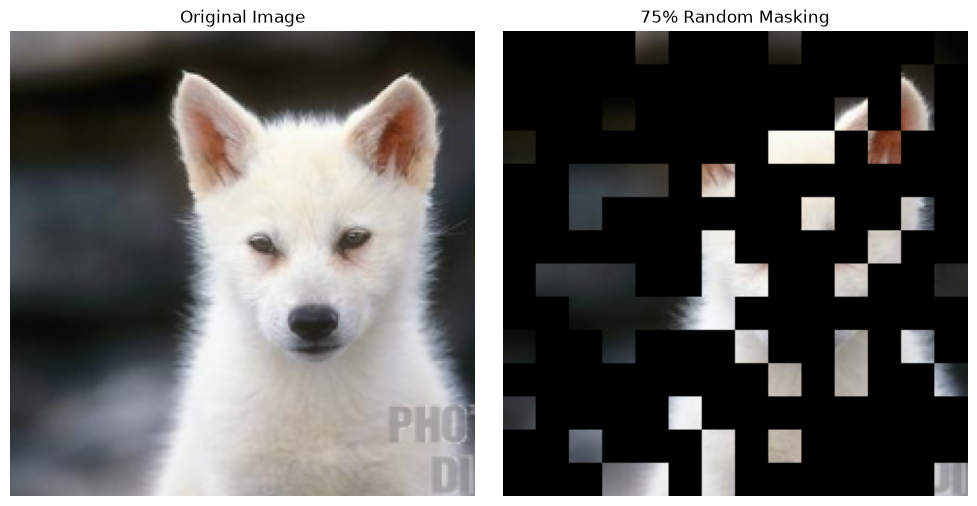

In [15]:
# First image and its corresponding mask
image = images[0].detach().cpu()
mask_grid = mask[0].reshape(14, 14).cpu()

# Expand patch mask to pixel resolution (224 × 224)
pixel_mask = mask_grid.repeat_interleave(16, dim=0).repeat_interleave(16, dim=1)

# Cover masked patches with black pixels
masked_image = image * (1 - pixel_mask.unsqueeze(0))

# Convert to image format [H, W, C]
original = image.permute(1, 2, 0).numpy()
masked = masked_image.permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original.clip(0, 1))
axes[0].set_title("Original Image")

axes[1].imshow(masked.clip(0, 1))
axes[1].set_title("75% Random Masking")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()



### Block 4.1: CLS Token Preparation

The MAE encoder receives 49 visible patch embeddings, each with
1024 features.

Before the Transformer blocks, we prepend a learnable
classification token (CLS) to the sequence.

The CLS token:
- Has the same embedding dimension as the patch tokens (1024).
- Is initialized with random values from N(0, 0.02²).
- Is updated through backpropagation during training.
- Receives its own fixed positional embedding.

**Operation:**

CLS = learnable_cls_token + cls_positional_embedding

Encoder_Input = Concatenate(CLS, Visible_Patches)

**Input:**  [B, 49, 1024]

**Output:** [B, 50, 1024]

The CLS token is added after random masking, following the
official MAE implementation.


In [17]:



embed_dim = 1024

# One learnable CLS token
cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))

# Initialize as in the official MAE implementation
nn.init.normal_(cls_token, std=0.02)

print("CLS token shape:", cls_token.shape)
print("Trainable:", cls_token.requires_grad)


CLS token shape: torch.Size([1, 1, 1024])
Trainable: True


In [18]:

# Number of images in the current batch
B = x_visible.shape[0]

# Add the CLS positional embedding
cls = cls_token + pos_embed[:, :1, :]

# Expand CLS token across the batch
cls_tokens = cls.expand(B, -1, -1)

# Prepend CLS token to the visible patch sequence
encoder_input = torch.cat(
    [cls_tokens, x_visible],
    dim=1
)

print("Visible patches:", x_visible.shape)
print("CLS tokens:", cls_tokens.shape)
print("Encoder input:", encoder_input.shape)


Visible patches: torch.Size([64, 49, 1024])
CLS tokens: torch.Size([64, 1, 1024])
Encoder input: torch.Size([64, 50, 1024])


In [19]:

# Verify dimensions
assert encoder_input.shape == (
    x_visible.shape[0], 50, 1024
)

# First token must be the CLS token
assert torch.allclose(
    encoder_input[:, :1, :],
    cls_tokens
)

# Remaining tokens must be unchanged visible patches
assert torch.allclose(
    encoder_input[:, 1:, :],
    x_visible
)

print("CLS token correctly prepended.")
print("Encoder input ready:", encoder_input.shape)


CLS token correctly prepended.
Encoder input ready: torch.Size([64, 50, 1024])



### Block 4.2.1: Layer Normalization 1 (LayerNorm)

https://docs.pytorch.org/docs/2.15/generated/torch.nn.LayerNorm.html

LayerNorm normalizes the 1024 features of each token independently.

It makes the feature values more consistently scaled, helping the
Transformer train stably, especially across many layers.

For each token, LayerNorm:

1. Calculates the mean and variance of its 1024 features.
2. Centers and scales those features.
3. Applies two learnable parameters: gamma (scale) and beta (shift).

LayerNorm does not combine information from different
tokens. Each token is normalized independently.

MAE uses Pre-LayerNorm: normalization happens before self-attention
and before the MLP.

Input:  [B, 50, 1024]
Output: [B, 50, 1024]


In [20]:
# First LayerNorm of the Transformer encoder block
norm1 = nn.LayerNorm(
    normalized_shape=1024,
    eps=1e-6,
    elementwise_affine=True
)

print(norm1)


LayerNorm((1024,), eps=1e-06, elementwise_affine=True, bias=True)


In [23]:

# Input from Block 4.1
print("Before LayerNorm:", encoder_input.shape)

# Apply normalization
x_norm1 = norm1(encoder_input)

print("After LayerNorm:", x_norm1.shape)


Before LayerNorm: torch.Size([64, 50, 1024])
After LayerNorm: torch.Size([64, 50, 1024])


In [22]:

# Examine the first patch token in the first image
token_before = encoder_input[0, 1, :]
token_after = x_norm1[0, 1, :]

print("Before normalization:")
print("Mean:", token_before.mean().item())
print("Std:", token_before.std(unbiased=False).item())

print("\nAfter normalization:")
print("Mean:", token_after.mean().item())
print("Std:", token_after.std(unbiased=False).item())

# Verify that LayerNorm preserves tensor dimensions
assert x_norm1.shape == encoder_input.shape


Before normalization:
Mean: 0.488558828830719
Std: 0.6054583787918091

After normalization:
Mean: -2.0721927285194397e-08
Std: 0.9999986886978149



### Block 4.2.2: Multi-Head Self-Attention (MHSA)

Multi-Head Self-Attention allows each token to gather information
from every other token in the sequence.

In MAE ViT-Large, the input contains:
- 1 CLS token + 49 visible patch tokens = 50 tokens
- 1024 features per token
- 16 parallel attention heads
- 64 features per head (1024 / 16)

**Process:**

1. Project input tokens into Query (Q), Key (K), and Value (V).
2. Split Q, K, and V into 16 attention heads.
3. Compute attention scores using Q × Kᵀ / sqrt(64).
4. Apply Softmax to obtain attention weights.
5. Multiply attention weights by V to aggregate information.
6. Concatenate the 16 heads.
7. Apply a final learned linear projection.

**Formula:**

Attention(Q, K, V) = Softmax(QKᵀ / sqrt(d_head)) × V

MHSA(X) = Concat(head_1, ..., head_16) × W_output + bias

**Input:**  [B, 50, 1024]
**Output:** [B, 50, 1024]

Attention changes the token representations, not their dimensions.

Only the 49 visible patches and CLS token participate.
The 147 masked patches are not processed by the encoder.


In [24]:

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim=1024, num_heads=16):
        super().__init__()

        assert embed_dim % num_heads == 0

        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.scale = self.head_dim ** -0.5

        # Combined linear projection for Q, K, V
        self.qkv = nn.Linear(
            embed_dim,
            3 * embed_dim,
            bias=True
        )

        # Final output projection
        self.proj = nn.Linear(embed_dim, embed_dim)

        # Initialization used by the original MAE model
        nn.init.xavier_uniform_(self.qkv.weight)
        nn.init.zeros_(self.qkv.bias)
        nn.init.xavier_uniform_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, x):
        B, N, D = x.shape

        # 1. Compute Q, K, V
        qkv = self.qkv(x)  # [B, N, 3*D]

        # 2. Split into attention heads
        qkv = qkv.reshape(
            B, N, 3, self.num_heads, self.head_dim
        )
        qkv = qkv.permute(2, 0, 3, 1, 4)

        q, k, v = qkv.unbind(0)
        # Each: [B, num_heads, N, head_dim]

        # 3. Scaled dot-product attention scores
        scores = (q @ k.transpose(-2, -1)) * self.scale

        # 4. Convert scores to attention weights
        attn_weights = scores.softmax(dim=-1)

        # 5. Weighted sum of Value vectors
        out = attn_weights @ v

        # 6. Concatenate the attention heads
        out = out.transpose(1, 2).reshape(B, N, D)

        # 7. Final output projection
        out = self.proj(out)

        return out


In [25]:

embed_dim = 1024
num_heads = 16

mhsa = MultiHeadSelfAttention(
    embed_dim=embed_dim,
    num_heads=num_heads
).to(x_norm1.device)

print("Number of heads:", mhsa.num_heads)
print("Dimension per head:", mhsa.head_dim)
print("Attention scaling factor:", mhsa.scale)


Number of heads: 16
Dimension per head: 64
Attention scaling factor: 0.125


In [26]:

# Input from LayerNorm 1
print("Input:", x_norm1.shape)

# Apply Multi-Head Self-Attention
x_attn = mhsa(x_norm1)

print("MHSA output:", x_attn.shape)


Input: torch.Size([64, 50, 1024])
MHSA output: torch.Size([64, 50, 1024])


In [27]:

B, N, D = x_norm1.shape

with torch.no_grad():
    # Combined Q, K, V projection
    qkv = mhsa.qkv(x_norm1)

    # Reshape and separate heads
    qkv = qkv.reshape(B, N, 3, 16, 64)
    qkv = qkv.permute(2, 0, 3, 1, 4)

    q, k, v = qkv.unbind(0)

    # Attention scores
    scores = (q @ k.transpose(-2, -1)) * mhsa.scale

    # Attention weights
    attention_weights = scores.softmax(dim=-1)

print("Q:", q.shape)
print("K:", k.shape)
print("V:", v.shape)
print("Attention scores:", scores.shape)
print("Attention weights:", attention_weights.shape)


Q: torch.Size([64, 16, 50, 64])
K: torch.Size([64, 16, 50, 64])
V: torch.Size([64, 16, 50, 64])
Attention scores: torch.Size([64, 16, 50, 50])
Attention weights: torch.Size([64, 16, 50, 50])


In [28]:

# Check output dimensions
assert x_attn.shape == x_norm1.shape

# Every attention distribution sums to 1
weight_sums = attention_weights.sum(dim=-1)

assert torch.allclose(
    weight_sums,
    torch.ones_like(weight_sums),
    atol=1e-5
)

# Check that outputs contain no NaN or infinite values
assert torch.isfinite(x_attn).all()

print("Attention weights sum to:",
      weight_sums[0, 0, 0].item())

print("All MHSA checks passed.")


Attention weights sum to: 1.0
All MHSA checks passed.
